# Lecture 5 — Class Exercise
## Distribution Charts: Airbnb London

> **Push to:** `week05/lecture05_exercise.ipynb`

**Rules:**
1. Cap price outliers at 95th percentile — annotate this
2. Every chart has a **median/mean reference line** with annotation
3. Insight title names the distribution shape or key finding
4. Colour has meaning — don't use colour just for decoration

---


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Load dataset
df = pd.read_csv("airbnb_london.csv")

# Display first 5 rows
display(df.head())

# Dataset information
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

,neighbourhood,room_type,price,minimum_nights,number_of_reviews,availability_365,reviews_per_month
0,Hammersmith,Entire home/apt,148.55,6,158,302,3.75
1,Kensington and Chelsea,Private room,393.56,29,46,323,2.56
2,Camden,Entire home/apt,197.64,19,242,291,2.52
3,Southwark,Private room,70.47,6,199,22,1.24
4,Hammersmith,Private room,96.58,18,110,103,4.11


Dataset shape: (2500, 7)

Column names:
['neighbourhood', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'availability_365', 'reviews_per_month']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   neighbourhood      2500 non-null   object 
 1   room_type          2500 non-null   object 
 2   price              2500 non-null   float64
 3   minimum_nights     2500 non-null   int64  
 4   number_of_reviews  2500 non-null   int64  
 5   availability_365   2500 non-null   int64  
 6   reviews_per_month  2500 non-null   float64
dtypes: float64(2), int64(3), object(2)
memory usage: 136.8+ KB


In [5]:
# Calculate 95th percentile of price
p95 = df['price'].quantile(0.95)

print("95th percentile price:", round(p95, 2))

# Cap prices at 95th percentile
df_cap = df[df['price'] <= p95].copy()

# Display summary statistics
print("\nPrice statistics by room type:")

display(
    df_cap.groupby('room_type')['price']
    .describe()
    .round(2)
)

95th percentile price: 372.66

Price statistics by room type:


,count,mean,std,min,25%,50%,75%,max
room_type,,,,,,,,
Entire home/apt,1251.0,176.30,75.65,28.05,119.64,163.42,223.51,372.61
Private room,942.0,87.30,39.53,20.92,59.01,78.57,105.96,277.93
Shared room,182.0,46.28,14.13,20.47,36.84,44.14,54.28,92.79


## Task 1 — Histogram: price by room type (overlapping distributions)

**What to build:** A histogram showing price distributions for **Entire home/apt vs Private room** (exclude Shared room — too few observations) overlaid on the same chart.

**Requirements:**
- Both room types on the same chart (use `color='room_type'`)
- `barmode='overlay'` with `opacity=0.6` so both distributions are visible
- A vertical line for the median of EACH room type, differently coloured
- Insight title comparing the two distributions

> 💡 `df_cap[df_cap['room_type'].isin(['Entire home/apt','Private room'])]`


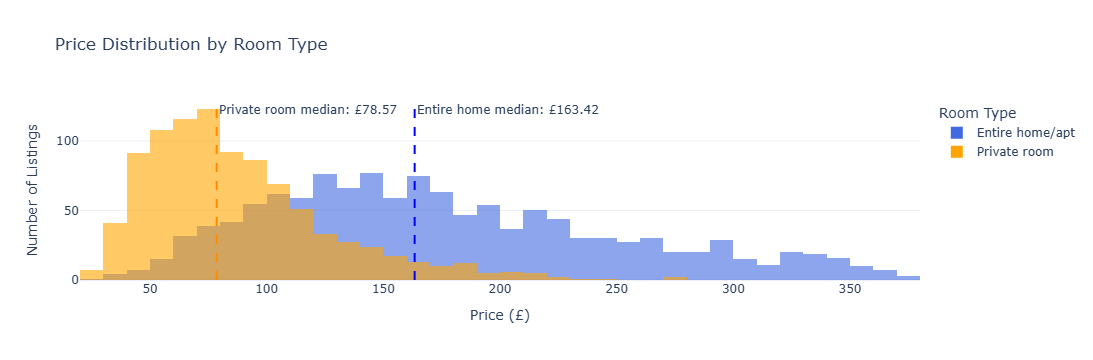

Entire home/apt median: 163.42
Private room median: 78.57


In [6]:
# Select two room types
df_task1 = df_cap[
    df_cap['room_type'].isin(
        ['Entire home/apt', 'Private room']
    )
].copy()

# Calculate median prices
median_entire = df_task1[
    df_task1['room_type'] == 'Entire home/apt'
]['price'].median()

median_private = df_task1[
    df_task1['room_type'] == 'Private room'
]['price'].median()

# Create histogram
fig = px.histogram(
    df_task1,
    x='price',
    color='room_type',
    barmode='overlay',
    opacity=0.6,
    nbins=50,
    color_discrete_map={
        'Entire home/apt': 'royalblue',
        'Private room': 'orange'
    },
    title='Price Distribution by Room Type'
)

# Add median lines
fig.add_vline(
    x=median_entire,
    line_dash='dash',
    line_color='blue',
    annotation_text=f'Entire home median: £{median_entire:.2f}'
)

fig.add_vline(
    x=median_private,
    line_dash='dash',
    line_color='darkorange',
    annotation_text=f'Private room median: £{median_private:.2f}'
)

# Update layout
fig.update_layout(
    xaxis_title='Price (£)',
    yaxis_title='Number of Listings',
    legend_title='Room Type',
    template='plotly_white'
)

fig.show()

# Display median values
print("Entire home/apt median:", round(median_entire, 2))
print("Private room median:", round(median_private, 2))

## Task 2 — Box plot: listing activity by borough

**What to build:** A **horizontal box plot** comparing listing activity (reviews per month) across London boroughs — reviews per month is a proxy for how frequently a listing is booked.

**Requirements:**
- Horizontal orientation (borough names are long)
- Sorted by median reviews per month (most active at top)
- Highlight the **two most active** boroughs in a different colour
- Outliers shown as individual points
- Insight title naming the two busiest boroughs

> 💡 Some listings have zero reviews — these are new or inactive listings. Filter them out with before plotting

Two most active neighbourhoods: ['Tower Hamlets', 'Hackney']


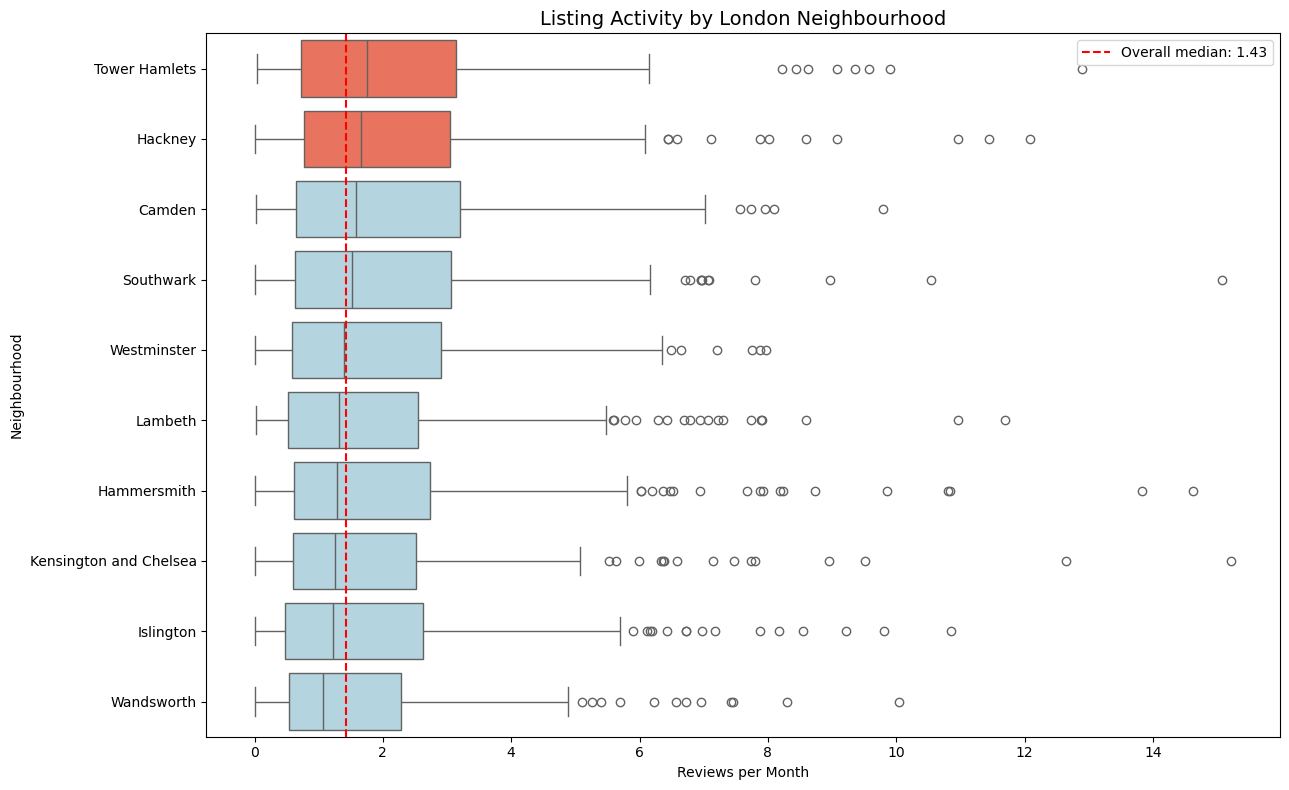

In [7]:
# Remove listings with zero reviews per month
df_task2 = df[df['reviews_per_month'] > 0].copy()

# Calculate median activity by neighbourhood
borough_medians = (
    df_task2.groupby('neighbourhood')['reviews_per_month']
    .median()
    .sort_values(ascending=False)
)

# Identify two most active neighbourhoods
top_two = borough_medians.head(2).index.tolist()

print("Two most active neighbourhoods:", top_two)

# Create colour palette
palette = {
    neighbourhood: (
        'tomato' if neighbourhood in top_two else 'lightblue'
    )
    for neighbourhood in borough_medians.index
}

# Calculate overall median
overall_median = df_task2['reviews_per_month'].median()

# Create box plot
plt.figure(figsize=(13, 8))

sns.boxplot(
    data=df_task2,
    x='reviews_per_month',
    y='neighbourhood',
    order=borough_medians.index,
    hue='neighbourhood',
    palette=palette,
    dodge=False,
    showfliers=True,
    legend=False
)

# Add overall median reference line
plt.axvline(
    overall_median,
    color='red',
    linestyle='--',
    label=f'Overall median: {overall_median:.2f}'
)

# Title and labels
plt.title(
    'Listing Activity by London Neighbourhood',
    fontsize=14
)

plt.xlabel('Reviews per Month')
plt.ylabel('Neighbourhood')

plt.legend()
plt.tight_layout()
plt.show()
